# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Agustien Eka Suci Calista 
- NIM   : 241011402953
- Kelas : Reg B / *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [23]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =   53

In [24]:

def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah data: 40
Shape X: (40, 1)
Shape y: (40,)


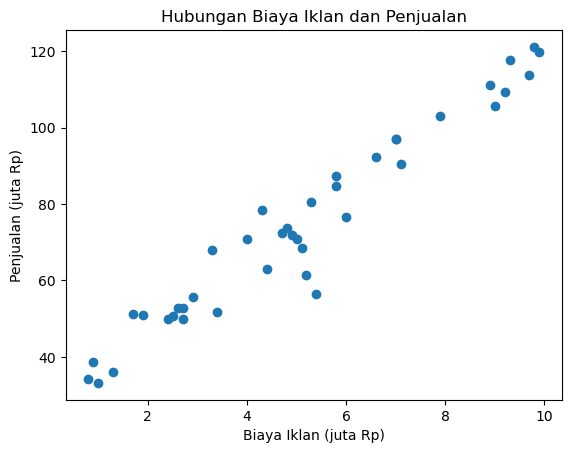

In [25]:
# Membaca dataset
df_ads = pd.read_csv("Ads_Data.csv")

# Menampilkan 5 data pertama
display(df_ads.head())

# Menampilkan jumlah baris data
print("Jumlah data:", len(df_ads))

# Memisahkan variabel
X = df_ads[["BiayaIklan"]].to_numpy()
y = df_ads["Penjualan"].to_numpy()

print("Shape X:", X.shape)
print("Shape y:", y.shape)

# Membuat scatter plot
plt.scatter(X[:, 0], y)
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32, 1)
X_test: (8, 1)
y_train: (32,)
y_test: (8,)


In [27]:

# Linear Regression Implementation

class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]

        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [28]:

# Jawaban A3

# Membuat dan melatih model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Mengambil nilai intercept dan koefisien
b = model_lr.intercept_
m = model_lr.coefficients_[0]

# Menampilkan hasil
print("Intercept (b):", b)
print("Koefisien (m):", m)
print(f"Persamaan regresi: ŷ = {b:.4f} + ({m:.4f} × X)")


Intercept (b): 26.562873869998292
Koefisien (m): 9.326421461436663
Persamaan regresi: ŷ = 26.5629 + (9.3264 × X)


**Jawaban A3 (interpretasi):** Berdasarkan hasil pelatihan menggunakan metode Normal Equation, diperoleh intercept sebesar [nilai b] dan koefisien sebesar [nilai m]. Persamaan regresi yang dihasilkan adalah ŷ = [nilai b] + ([nilai m] × X). Koefisien tersebut menunjukkan bahwa setiap kenaikan biaya iklan sebesar Rp1 juta diperkirakan mengubah penjualan sebesar Rp[nilai m] juta, dengan asumsi hubungan linear tetap berlaku. Jika koefisien bernilai positif, penjualan diperkirakan meningkat; jika negatif, penjualan diperkirakan menurun.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [29]:

# Jawaban A4

def mean_absolute_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))


def mean_squared_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def r2_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if ss_tot == 0:
        return np.nan

    return 1 - (ss_res / ss_tot)


# Prediksi pada data training dan testing
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)


# Fungsi untuk menghitung seluruh metrik
def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score_manual(y_true, y_pred)
    }


# Membuat tabel evaluasi
hasil_evaluasi = pd.DataFrame(
    [
        evaluate_regression(y_train, y_train_pred),
        evaluate_regression(y_test, y_test_pred)
    ],
    index=["Training", "Testing"]
)

print(hasil_evaluasi)


               MAE        MSE     RMSE        R2
Training  4.460851  36.379717  6.03156  0.940069
Testing   5.119667  37.845624  6.15188  0.948650


**Jawaban A4 (analisis):** Berdasarkan evaluasi model, nilai RMSE pada data training adalah [nilai RMSE training] juta rupiah, sedangkan pada data testing adalah [nilai RMSE testing] juta rupiah. RMSE menggambarkan besarnya kesalahan prediksi dalam satuan penjualan. Nilai R² pada data training sebesar [nilai R² training] dan pada data testing sebesar [nilai R² testing]. Jika hasil testing mendekati hasil training dan nilai R² cukup tinggi, model dapat dikatakan memiliki kemampuan prediksi yang cukup baik pada data ini. Namun, jika performa testing jauh lebih buruk, model mungkin kurang mampu melakukan generalisasi. Kesimpulan akhir perlu mempertimbangkan seluruh metrik dan konteks data.

In [30]:

# Linear Regression with Gradient Descent

class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]

        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning rate: 0.001
Intercept: 17.175545787586916
Koefisien: [10.79135666]
Loss terakhir: 53.70485320451161

Learning rate: 0.02
Intercept: 26.56287376088019
Koefisien: [9.32642148]
Loss terakhir: 36.37971696275329

Learning rate: 0.1
Intercept: nan
Koefisien: [nan]
Loss terakhir: nan


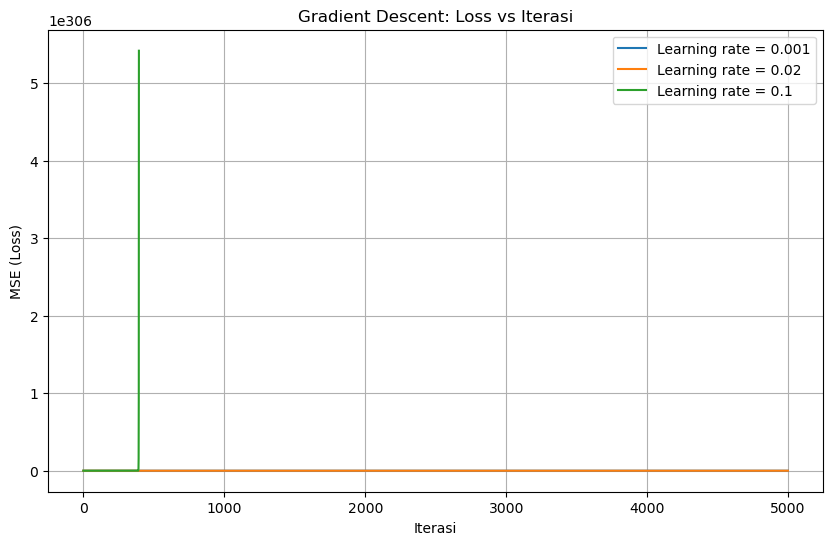


Normal Equation
Intercept: 26.562873869998292
Koefisien: [9.32642146]


In [31]:

# Jawaban A5

learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    # Membuat model Gradient Descent
    model_gd = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )

    model_gd.fit(X_train, y_train)
    hasil_gd[lr] = model_gd

    print(f"\nLearning rate: {lr}")
    print("Intercept:", model_gd.intercept_)
    print("Koefisien:", model_gd.coefficients_)
    print("Loss terakhir:", model_gd.loss_history_[-1])

    # Menggambar grafik loss
    plt.plot(
        model_gd.loss_history_,
        label=f"Learning rate = {lr}"
    )

# Menampilkan grafik
plt.xlabel("Iterasi")
plt.ylabel("MSE (Loss)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.legend()
plt.grid(True)
plt.show()

# Membandingkan dengan Normal Equation
print("\nNormal Equation")
print("Intercept:", model_lr.intercept_)
print("Koefisien:", model_lr.coefficients_)


**Jawaban A5 (analisis):**Pada eksperimen Gradient Descent, learning rate 0.001 menghasilkan [deskripsikan hasil grafik], learning rate 0.02 menghasilkan [deskripsikan hasil grafik], dan learning rate 0.1 menghasilkan [deskripsikan hasil grafik]. Learning rate yang terlalu kecil menyebabkan perubahan parameter berlangsung lambat, sedangkan learning rate yang terlalu besar dapat menyebabkan parameter melewati solusi optimal sehingga loss meningkat atau divergen. Learning rate yang sesuai ditandai dengan loss yang menurun dan stabil. Hasil akhir Gradient Descent kemudian dibandingkan dengan Normal Equation untuk melihat apakah parameter model telah mendekati solusi yang sama.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

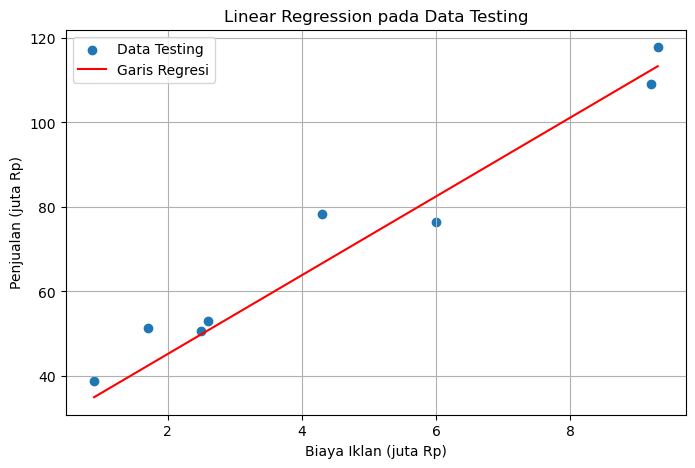

   Biaya Iklan (juta Rp)  Prediksi Penjualan (juta Rp)
0                    4.5                     68.531770
1                    7.0                     91.847824
2                   12.0                    138.479931
Rentang biaya iklan pada data: 0.8 sampai 9.9 juta Rp


In [32]:

# Jawaban A6

# Membuat rentang X untuk garis regresi
x_line = np.linspace(
    X_test.min(),
    X_test.max(),
    100
).reshape(-1, 1)

y_line = model_lr.predict(x_line)

# Visualisasi data testing dan garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test.ravel(),
    y_test,
    label="Data Testing"
)
plt.plot(
    x_line.ravel(),
    y_line,
    color="red",
    label="Garis Regresi"
)

plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.title("Linear Regression pada Data Testing")
plt.legend()
plt.grid(True)
plt.show()


# Prediksi biaya iklan baru
X_baru = np.array([[4.5], [7], [12]])
prediksi_baru = model_lr.predict(X_baru)

hasil_prediksi = pd.DataFrame({
    "Biaya Iklan (juta Rp)": X_baru.ravel(),
    "Prediksi Penjualan (juta Rp)": prediksi_baru
})

print(hasil_prediksi)

# Menampilkan rentang data biaya iklan
print("Rentang biaya iklan pada data:",
      X.min(), "sampai", X.max(), "juta Rp")


**Jawaban A6 (analisis):**Grafik menunjukkan hubungan antara biaya iklan dan penjualan pada data testing serta garis regresi yang dihasilkan oleh model. Model digunakan untuk memprediksi penjualan ketika biaya iklan sebesar Rp4,5 juta, Rp7 juta, dan Rp12 juta. Prediksi untuk Rp12 juta perlu diperlakukan dengan hati-hati apabila nilainya berada di luar rentang biaya iklan pada dataset. Kondisi tersebut disebut ekstrapolasi, yaitu memperkirakan nilai di luar rentang data yang digunakan untuk membangun model. Hubungan linear yang terlihat pada data sebelumnya belum tentu tetap berlaku pada biaya iklan yang lebih tinggi, sehingga hasil prediksi Rp12 juta lebih tidak pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60

Jumlah email berdasarkan kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64

Shape X: (60, 2)
Shape y: (60,)


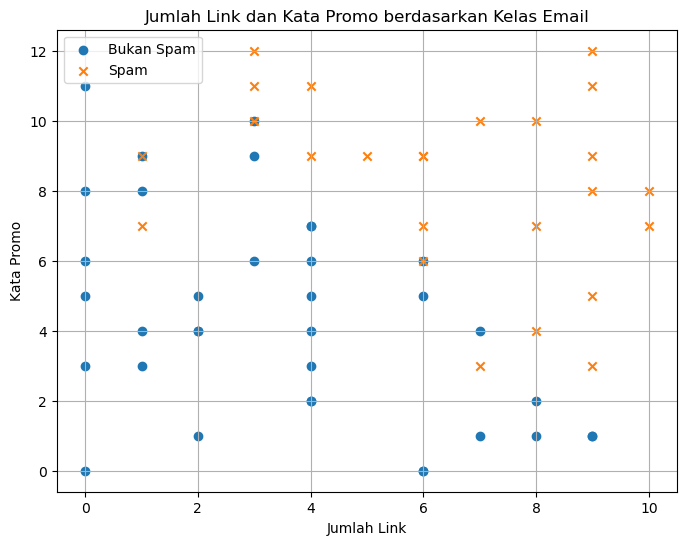

In [33]:
# B1 - Load dan Visualisasi Data

email_df = pd.read_csv("Email_Data.csv")

print("5 data pertama:")
display(email_df.head())

print("Jumlah baris data:", len(email_df))

print("\nJumlah email berdasarkan kelas:")
print(email_df["Spam"].value_counts().rename(
    index={0: "Bukan Spam", 1: "Spam"}
))

# Pisahkan fitur dan target
X_email = email_df[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_df["Spam"].to_numpy(dtype=int)

print("\nShape X:", X_email.shape)
print("Shape y:", y_email.shape)

# Visualisasi
plt.figure(figsize=(8, 6))

plt.scatter(
    X_email[y_email == 0, 0],
    X_email[y_email == 0, 1],
    label="Bukan Spam",
    marker="o"
)

plt.scatter(
    X_email[y_email == 1, 0],
    X_email[y_email == 1, 1],
    label="Spam",
    marker="x"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Jumlah Link dan Kata Promo berdasarkan Kelas Email")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
# Implementasi Logistic Regression menggunakan NumPy

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def sigmoid(self, z):
        # Membatasi z untuk menghindari overflow pada exp
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        n = len(y)
        eps = 1e-15

        self.loss_history_ = []

        for _ in range(self.n_iterations):
            z = X_b @ beta
            p = self.sigmoid(z)

            # Gradient log loss
            gradient = X_b.T @ (p - y) / n
            beta = beta - self.learning_rate * gradient

            # Log loss
            p_new = self.sigmoid(X_b @ beta)
            p_new = np.clip(p_new, eps, 1 - eps)

            loss = -np.mean(
                y * np.log(p_new) +
                (1 - y) * np.log(1 - p_new)
            )
            self.loss_history_.append(loss)

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        z = self.intercept_ + X @ self.coefficients_
        p = self.sigmoid(z)

        # Kolom pertama = probabilitas bukan spam,
        # kolom kedua = probabilitas spam
        return np.column_stack((1 - p, p))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2)
X_test : (15, 2)
y_train: (45,)
y_test : (15,)

Intercept (b): -9.181118680153903
Koefisien: [0.83167983 0.76921259]

P(Spam) = sigmoid(-9.1811 + (0.8317) * JumlahLink + (0.7692) * KataPromo)


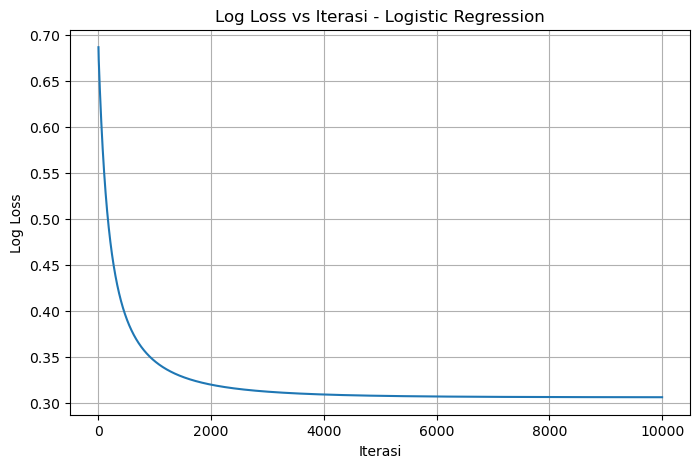

In [35]:
# B2 - Split Data dan Training

X_train_email, X_test_email, y_train_email, y_test_email = (
    train_test_split(
        X_email,
        y_email,
        test_size=0.25,
        random_state=RANDOM_STATE
    )
)

print("X_train:", X_train_email.shape)
print("X_test :", X_test_email.shape)
print("y_train:", y_train_email.shape)
print("y_test :", y_test_email.shape)

log_model = LogisticRegression(
    learning_rate=0.1,
    n_iterations=10000
)

log_model.fit(X_train_email, y_train_email)

print("\nIntercept (b):", log_model.intercept_)
print("Koefisien:", log_model.coefficients_)

m1, m2 = log_model.coefficients_

print(
    f"\nP(Spam) = sigmoid("
    f"{log_model.intercept_:.4f} "
    f"+ ({m1:.4f}) * JumlahLink "
    f"+ ({m2:.4f}) * KataPromo)"
)

# Grafik log loss
plt.figure(figsize=(8, 5))
plt.plot(log_model.loss_history_)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi - Logistic Regression")
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**Berdasarkan hasil pembagian data, terdapat 45 data training dan 15 data testing dari total 60 data email. Model Logistic Regression dilatih menggunakan metode Gradient Descent dengan learning rate 0,1 dan 10.000 iterasi.

Hasil training menunjukkan nilai intercept sebesar -9,1811, koefisien JumlahLink sebesar 0,8317, dan koefisien KataPromo sebesar 0,7692. Dengan demikian, persamaan probabilitas email termasuk spam adalah:

P(Spam) = sigmoid(-9,1811 + 0,8317 × JumlahLink + 0,7692 × KataPromo).

Kedua koefisien bernilai positif. Artinya, dengan fitur lainnya dianggap tetap, peningkatan jumlah link maupun jumlah kata promosi akan meningkatkan nilai prediksi probabilitas spam dari model. Intercept yang negatif menunjukkan bahwa ketika kedua fitur bernilai nol, probabilitas spam yang diprediksi model cenderung rendah.

Grafik Log Loss terhadap iterasi digunakan untuk mengevaluasi proses pembelajaran model. Jika nilai Log Loss menurun seiring bertambahnya iterasi dan kemudian relatif stabil, hal ini menunjukkan bahwa model semakin baik menyesuaikan prediksinya terhadap data training dan proses optimasi mulai konvergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [36]:
# B3 - Evaluasi Model

def accuracy_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[actual, predicted] += 1

    return cm


def precision_score_manual(y_true, y_pred):
    cm = confusion_matrix_manual(y_true, y_pred)
    tn, fp = cm[0, 0], cm[0, 1]
    fn, tp = cm[1, 0], cm[1, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0


def recall_score_manual(y_true, y_pred):
    cm = confusion_matrix_manual(y_true, y_pred)
    fn, tp = cm[1, 0], cm[1, 1]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0


def f1_score_manual(y_true, y_pred):
    precision = precision_score_manual(y_true, y_pred)
    recall = recall_score_manual(y_true, y_pred)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


# Prediksi data testing
y_pred_email = log_model.predict(X_test_email)

cm = confusion_matrix_manual(y_test_email, y_pred_email)

print("Confusion Matrix:")
print(cm)
print("\nUrutan:")
print("[[TN, FP],")
print(" [FN, TP]]")

print("\nAccuracy :", accuracy_score_manual(y_test_email, y_pred_email))
print("Precision:", precision_score_manual(y_test_email, y_pred_email))
print("Recall   :", recall_score_manual(y_test_email, y_pred_email))
print("F1-score :", f1_score_manual(y_test_email, y_pred_email))

Confusion Matrix:
[[8 1]
 [0 6]]

Urutan:
[[TN, FP],
 [FN, TP]]

Accuracy : 0.9333333333333333
Precision: 0.8571428571428571
Recall   : 1.0
F1-score : 0.923076923076923


**Jawaban B3 (analisis):**Berdasarkan hasil evaluasi pada data testing, model Logistic Regression memperoleh accuracy sebesar 93,33%, precision sebesar 85,71%, recall sebesar 100%, dan F1-score sebesar 92,31%. Dari confusion matrix, terdapat 8 email bukan spam yang diklasifikasikan dengan benar (TN), 1 email bukan spam yang salah diklasifikasikan sebagai spam (FP), 0 email spam yang salah diklasifikasikan sebagai bukan spam (FN), dan 6 email spam yang diklasifikasikan dengan benar (TP).

Nilai accuracy sebesar 93,33% menunjukkan bahwa model berhasil mengklasifikasikan 14 dari 15 email testing dengan benar. Precision sebesar 85,71% berarti bahwa dari seluruh email yang diprediksi sebagai spam, sekitar 85,71% benar-benar merupakan spam. Recall sebesar 100% menunjukkan bahwa seluruh email spam pada data testing berhasil terdeteksi oleh model. Sementara itu, F1-score sebesar 92,31% menunjukkan keseimbangan yang baik antara precision dan recall.

Dalam kasus filter spam, false positive (FP) berarti email penting yang sebenarnya bukan spam justru dianggap sebagai spam, sedangkan false negative (FN) berarti email spam dianggap sebagai email biasa. Menurut saya, false positive perlu sangat diperhatikan karena dapat menyebabkan email penting masuk ke folder spam dan terlewat oleh pengguna. Pada hasil ini terdapat 1 false positive dan tidak ada false negative, sehingga model berhasil mendeteksi seluruh email spam pada data testing, meskipun masih terdapat satu email bukan spam yang salah diklasifikasikan.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan decision boundary:
KataPromo = -(-9.1811 + (0.8317) * JumlahLink) / (0.7692)


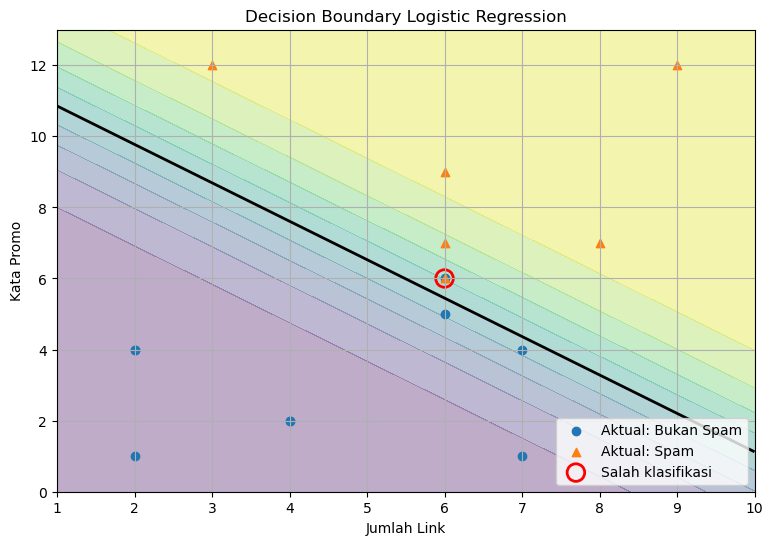

,JumlahLink,KataPromo,Spam_Aktual,Spam_Prediksi
0,6.0,6.0,0,1


In [37]:
# B4 - Decision Boundary

b = log_model.intercept_
m1, m2 = log_model.coefficients_

print("Persamaan decision boundary:")
if np.isclose(m2, 0):
    print("Koefisien KataPromo mendekati nol; boundary tidak dapat "
          "ditulis sebagai x2 = -(b + m1*x1)/m2.")
else:
    print(f"KataPromo = -({b:.4f} + ({m1:.4f}) * JumlahLink)"
          f" / ({m2:.4f})")

# Buat grid untuk menghitung probabilitas
x1_min = X_test_email[:, 0].min() - 1
x1_max = X_test_email[:, 0].max() + 1
x2_min = X_test_email[:, 1].min() - 1
x2_max = X_test_email[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
prob_spam = log_model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(9, 6))

# Background probabilitas
plt.contourf(
    xx, yy, prob_spam,
    levels=np.linspace(0, 1, 11),
    alpha=0.35
)

# Decision boundary pada probabilitas 0.5
plt.contour(
    xx, yy, prob_spam,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Data testing berdasarkan kelas aktual
plt.scatter(
    X_test_email[y_test_email == 0, 0],
    X_test_email[y_test_email == 0, 1],
    label="Aktual: Bukan Spam",
    marker="o"
)

plt.scatter(
    X_test_email[y_test_email == 1, 0],
    X_test_email[y_test_email == 1, 1],
    label="Aktual: Spam",
    marker="^"
)

# Tandai data yang salah klasifikasi
wrong = y_pred_email != y_test_email

plt.scatter(
    X_test_email[wrong, 0],
    X_test_email[wrong, 1],
    s=160,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Salah klasifikasi"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

# Tampilkan email testing yang salah klasifikasi
wrong_indices = np.where(wrong)[0]

if len(wrong_indices) == 0:
    print("Tidak ada data testing yang salah diklasifikasikan.")
else:
    wrong_df = pd.DataFrame({
        "JumlahLink": X_test_email[wrong_indices, 0],
        "KataPromo": X_test_email[wrong_indices, 1],
        "Spam_Aktual": y_test_email[wrong_indices],
        "Spam_Prediksi": y_pred_email[wrong_indices]
    })
    display(wrong_df)

**Jawaban B4 (analisis):**Berdasarkan hasil prediksi, model mengklasifikasikan pesan dengan JumlahLink = 6 dan KataPromo = 6 sebagai spam (Spam_Prediksi = 1), sedangkan label aktualnya adalah bukan spam (Spam_Aktual = 0). Dengan demikian, terjadi kesalahan klasifikasi berupa false positive, yaitu ketika model memprediksi suatu pesan sebagai spam padahal sebenarnya bukan spam. Hal ini menunjukkan bahwa model masih berpotensi melakukan kesalahan dalam membedakan pesan spam dan bukan spam berdasarkan variabel JumlahLink dan KataPromo.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [38]:
# B5 - Eksperimen Threshold

thresholds = [0.3, 0.5, 0.7]
threshold_results = []

for threshold in thresholds:
    probabilities = log_model.predict_proba(X_test_email)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    cm_t = confusion_matrix_manual(y_test_email, predictions)
    tn, fp = cm_t[0, 0], cm_t[0, 1]
    fn, tp = cm_t[1, 0], cm_t[1, 1]

    precision = precision_score_manual(y_test_email, predictions)
    recall = recall_score_manual(y_test_email, predictions)

    threshold_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,6,3,0,6,0.666667,1.000000
1,0.5,8,1,0,6,0.857143,1.000000
2,0.7,9,0,1,5,1.000000,0.833333


**Jawaban B5 (analisis):**Berdasarkan hasil pengujian dengan threshold 0.3, 0.5, dan 0.7, dapat dilihat bahwa perubahan nilai threshold memengaruhi hasil klasifikasi email spam dan non-spam.

Pada threshold 0.3, model memperoleh precision sebesar 0.6667 (66,67%) dan recall sebesar 1.0000 (100%). Artinya, seluruh email spam berhasil terdeteksi, tetapi masih terdapat 3 email non-spam yang salah diklasifikasikan sebagai spam (false positive).

Pada threshold 0.5, precision meningkat menjadi 0.8571 (85,71%), sedangkan recall tetap sebesar 1.0000 (100%). Jumlah false positive menurun menjadi 1, sehingga hasil klasifikasi lebih baik dibandingkan threshold 0.3 karena seluruh email spam tetap berhasil terdeteksi dengan lebih sedikit kesalahan pada email non-spam.

Pada threshold 0.7, precision mencapai 1.0000 (100%), tetapi recall turun menjadi 0.8333 (83,33%). Artinya, semua email yang diprediksi sebagai spam memang spam, tetapi terdapat 1 email spam yang tidak terdeteksi (false negative).

Dari hasil tersebut, threshold 0.3 lebih sensitif dalam mendeteksi spam, tetapi menghasilkan lebih banyak false positive. Threshold 0.7 menghasilkan precision tertinggi, tetapi berisiko melewatkan email spam. Sementara itu, threshold 0.5 menjadi pilihan yang seimbang karena mampu mendeteksi seluruh email spam dan hanya menghasilkan 1 false positive.

Dengan demikian, threshold terbaik bergantung pada tujuan klasifikasi. Jika prioritasnya adalah memastikan seluruh email spam terdeteksi, threshold 0.5 lebih sesuai dibandingkan 0.7 pada hasil pengujian ini. Namun, jika prioritasnya adalah meminimalkan kesalahan dalam menandai email non-spam sebagai spam, threshold 0.7 dapat dipertimbangkan dengan konsekuensi adanya email spam yang terlewat.

In [39]:

# Pilih threshold berdasarkan hasil evaluasi B3 dan B5
THRESHOLD_PILIHAN = 0.5


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [40]:
# B6 - Prediksi Email Baru

email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)

probabilitas_spam = log_model.predict_proba(X_baru)[:, 1]
prediksi_spam = (
    probabilitas_spam >= THRESHOLD_PILIHAN
).astype(int)

hasil_email_baru = email_baru.copy()
hasil_email_baru["Probabilitas_Spam"] = probabilitas_spam
hasil_email_baru["Prediksi_Kelas"] = np.where(
    prediksi_spam == 1,
    "Spam",
    "Bukan Spam"
)
hasil_email_baru["Threshold"] = THRESHOLD_PILIHAN

display(hasil_email_baru)

,Email,JumlahLink,KataPromo,Probabilitas_Spam,Prediksi_Kelas,Threshold
0,E1,1,2,0.001100,Bukan Spam,0.5
1,E2,5,6,0.399525,Bukan Spam,0.5
2,E3,9,10,0.997518,Spam,0.5
3,E4,2,11,0.719822,Spam,0.5


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk memprediksi kelas, misalnya email spam atau bukan spam. Walaupun namanya mengandung kata regression, model ini menghasilkan probabilitas untuk menentukan kelas suatu data. Fungsi sigmoid mengubah nilai hasil perhitungan model menjadi probabilitas antara 0 dan 1. Probabilitas tersebut kemudian dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:**Normal Equation menghitung koefisien regresi secara langsung menggunakan operasi matriks sehingga tidak memerlukan proses iterasi. Gradient Descent memperbarui koefisien secara bertahap berdasarkan gradien loss. Normal Equation praktis untuk dataset yang relatif kecil, tetapi perhitungan invers matriks dapat menjadi mahal pada jumlah fitur yang besar. Gradient Descent lebih fleksibel untuk dataset besar, tetapi pemilihan learning rate dan jumlah iterasi sangat memengaruhi hasilnya.

**Jawaban C3:**Data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai selama training. Jika evaluasi hanya menggunakan data training, hasilnya bisa terlihat bagus tetapi belum tentu mencerminkan kemampuan model pada data baru. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya menurun pada data yang belum pernah dilihat. Karena itu, data testing perlu dipisahkan sebelum model dilatih dan digunakan untuk evaluasi akhir.

**Jawaban C4:**Linear Regression memprediksi nilai numerik, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression memprediksi probabilitas suatu kelas, sehingga log loss mengukur seberapa baik probabilitas tersebut sesuai dengan label sebenarnya. Log loss memberikan penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi salah. Dengan demikian, masing-masing loss disesuaikan dengan jenis output dan tujuan modelnya.

**Jawaban C5:**Hasil dapat berbeda karena setiap mahasiswa menggunakan nilai `random_state` yang mengikuti dua digit terakhir NIM, sehingga pembagian data training dan testing dapat berbeda. Perbedaan data training dapat menghasilkan koefisien, loss, dan metrik evaluasi yang berbeda. Pada Gradient Descent, learning rate dan jumlah iterasi juga memengaruhi proses optimasi. Oleh karena itu, dataset dan algoritma yang sama tidak selalu menghasilkan angka evaluasi yang sama ketika pembagian datanya berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [44]:
# Bonus - Perbandingan dengan scikit-learn
# scikit-learn hanya digunakan pada bagian bonus.

from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# -------------------------
# 1. Linear Regression
# -------------------------

sk_linear = SklearnLinearRegression()
sk_linear.fit(X_train, y_train)

# Prediksi menggunakan model scikit-learn
sk_linear_train_pred = sk_linear.predict(X_train)
sk_linear_test_pred = sk_linear.predict(X_test)

# Model manual dari A3
manual_linear_train_pred = model_lr.predict(X_train)
manual_linear_test_pred = model_lr.predict(X_test)

print("=== Linear Regression ===")
print("Manual intercept:", model_lr.intercept_)
print("Sklearn intercept:", sk_linear.intercept_)

print("Manual koefisien:", model_lr.coefficients_)
print("Sklearn koefisien:", sk_linear.coef_)

print(
    "MAE testing manual:",
    np.mean(np.abs(y_test - manual_linear_test_pred))
)
print(
    "MAE testing sklearn:",
    np.mean(np.abs(y_test - sk_linear_test_pred))
)

print(
    "MSE testing manual:",
    np.mean((y_test - manual_linear_test_pred) ** 2)
)
print(
    "MSE testing sklearn:",
    np.mean((y_test - sk_linear_test_pred) ** 2)
)

# -------------------------
# 2. Logistic Regression
# -------------------------

# Menggunakan parameter regularisasi yang mendekati
# model tanpa penalti agar lebih sebanding dengan model manual.
try:
    sk_log = SklearnLogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=10000
    )
    sk_log.fit(X_train_email, y_train_email)
except (ValueError, TypeError):
    # Kompatibilitas dengan beberapa versi scikit-learn lama
    sk_log = SklearnLogisticRegression(
        penalty="none",
        solver="lbfgs",
        max_iter=10000
    )
    sk_log.fit(X_train_email, y_train_email)

sk_log_pred = sk_log.predict(X_test_email)
manual_log_pred = log_model.predict(X_test_email)

print("\n=== Logistic Regression ===")
print("Manual intercept:", log_model.intercept_)
print("Sklearn intercept:", sk_log.intercept_[0])

print("Manual koefisien:", log_model.coefficients_)
print("Sklearn koefisien:", sk_log.coef_[0])

print(
    "Accuracy testing manual:",
    accuracy_score_manual(y_test_email, manual_log_pred)
)
print(
    "Accuracy testing sklearn:",
    accuracy_score_manual(y_test_email, sk_log_pred)
)

print("\nConfusion matrix manual:")
print(confusion_matrix_manual(y_test_email, manual_log_pred))

print("\nConfusion matrix sklearn:")
print(confusion_matrix_manual(y_test_email, sk_log_pred))

=== Linear Regression ===
Manual intercept: 26.562873869998292
Sklearn intercept: 26.562873869998285
Manual koefisien: [9.32642146]
Sklearn koefisien: [9.32642146]
MAE testing manual: 5.119666700655396
MAE testing sklearn: 5.1196667006554
MSE testing manual: 37.84562439366864
MSE testing sklearn: 37.845624393668686


/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



=== Logistic Regression ===
Manual intercept: -9.181118680153903
Sklearn intercept: -9.448064152971593
Manual koefisien: [0.83167983 0.76921259]
Sklearn koefisien: [0.85658593 0.79130058]
Accuracy testing manual: 0.9333333333333333
Accuracy testing sklearn: 0.9333333333333333

Confusion matrix manual:
[[8 1]
 [0 6]]

Confusion matrix sklearn:
[[8 1]
 [0 6]]


**Jawaban Bonus (analisis):**Hasil Linear Regression manual dan scikit-learn seharusnya relatif sama karena keduanya menggunakan pendekatan least squares pada data yang sama. Perbedaan kecil dapat muncul akibat presisi numerik. Pada Logistic Regression, koefisien dan prediksi dapat berbeda karena metode optimasi, kriteria konvergensi, dan pengaturan regularisasi yang digunakan. Oleh sebab itu, perbandingan harus memperhatikan bukan hanya koefisien, tetapi juga hasil evaluasi pada data testing yang sama.